# 10 - Deterioration factors and agreement with the Random Survival Forest

Two questions:

1. Which bridge characteristics (age, traffic, length, material, structural type) are associated with an earlier first drop from Good to Fair or Poor? This uses Kaplan-Meier curves on the training histories.
2. Does our strongest model, the improved Random Survival Forest, rank those same groups the same way?

The event is the first drop from Good to Fair or Poor. The clock starts at the first observed Good year. All comparisons are unadjusted and describe associations, not causes.

# 1. Data Loading and Inspection

Load the training dataset and inspect its structure, variables, and missing values before conducting Kaplan-Meier survival analysis.

In [2]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if project_root.name == "bridge_time_primary_notebooks":
    project_root = project_root.parent

train = pd.read_parquet(
    project_root / "data/final/bridge_survival_train.parquet"
)

print("Dataset shape:", train.shape)

print("\nColumn names:")
print(train.columns.tolist())

print("\nFirst five rows:")
display(train.head())

print("\nMissing values:")
print(train.isna().sum())

Dataset shape: (498875, 14)

Column names:
['bridge_id', 'start_year', 'bridge_age', 'YEAR_BUILT_027', 'YEAR_RECONSTRUCTED_106', 'ADT_029', 'STRUCTURE_KIND_043A', 'STRUCTURE_TYPE_043B', 'STRUCTURE_LEN_MT_049', 'end_year', 'event', 'stop_reason', 'last_year', 'duration']

First five rows:


,bridge_id,start_year,bridge_age,YEAR_BUILT_027,YEAR_RECONSTRUCTED_106,ADT_029,STRUCTURE_KIND_043A,STRUCTURE_TYPE_043B,STRUCTURE_LEN_MT_049,end_year,event,stop_reason,last_year,duration
0,01_00000000000S700,1996,7.0,1989.0,0.0,80.0,5,01,11.0,1999.0,1,Deterioration,2005,3.0
1,01_00000000000S702,2003,4.0,1999.0,0.0,50.0,5,05,14.7,2020.0,0,Training cutoff,2025,17.0
2,01_00000000000S703,2006,4.0,2002.0,0.0,150.0,5,01,13.7,2020.0,0,Training cutoff,2025,14.0
3,01_0000000000M0022,1998,56.0,1942.0,0.0,800.0,1,02,43.3,2006.0,1,Deterioration,2025,8.0
4,01_00000BLN0BR0010,2012,38.0,1974.0,0.0,250.0,1,19,6.4,2015.0,1,Deterioration,2025,3.0



Missing values:
bridge_id                     0
start_year                    0
bridge_age                 1449
YEAR_BUILT_027             1161
YEAR_RECONSTRUCTED_106    25306
ADT_029                    2003
STRUCTURE_KIND_043A         348
STRUCTURE_TYPE_043B         389
STRUCTURE_LEN_MT_049        230
end_year                      0
event                         0
stop_reason                   0
last_year                     0
duration                      0
dtype: int64


# 2. Survival Data Validation

Check the event distribution, observation durations, and censoring reasons before estimating Kaplan-Meier survival curves.

In [3]:
print("Total bridges:", len(train))

print("\nEvent distribution:")
print(train["event"].value_counts().sort_index())

print("\nEvent percentages:")
print((train["event"].value_counts(normalize=True) * 100).round(2))

print("\nCensoring and stop reasons:")
print(train["stop_reason"].value_counts())

print("\nDuration summary (years):")
print(train["duration"].describe())

print("\nData validation:")
print("Negative durations:", (train["duration"] < 0).sum())
print("Zero durations:", (train["duration"] == 0).sum())
print("Invalid event values:", (~train["event"].isin([0, 1])).sum())
print(
    "End-year inconsistencies:",
    ((train["end_year"] - train["start_year"] - train["duration"]).abs() > 0.001).sum()
)

Total bridges: 498875

Event distribution:
event
0    261678
1    237197
Name: count, dtype: int64

Event percentages:
event
0    52.45
1    47.55
Name: proportion, dtype: float64

Censoring and stop reasons:
stop_reason
Deterioration         237197
Training cutoff       169363
End of observation     75739
Structure change       10265
Observation gap         3964
Unknown condition       2347
Name: count, dtype: int64

Duration summary (years):
count    498875.000000
mean         11.613126
std           8.605542
min           1.000000
25%           4.000000
50%           9.000000
75%          18.000000
max          28.000000
Name: duration, dtype: float64

Data validation:
Negative durations: 0
Zero durations: 0
Invalid event values: 0
End-year inconsistencies: 0


# 3. Kaplan-Meier Analysis by Bridge Age

Compare time to first drop from Good across bridge age groups using Kaplan-Meier survival curves.

Bridge age is measured at the start of observation. The analysis describes associations rather than causal effects.

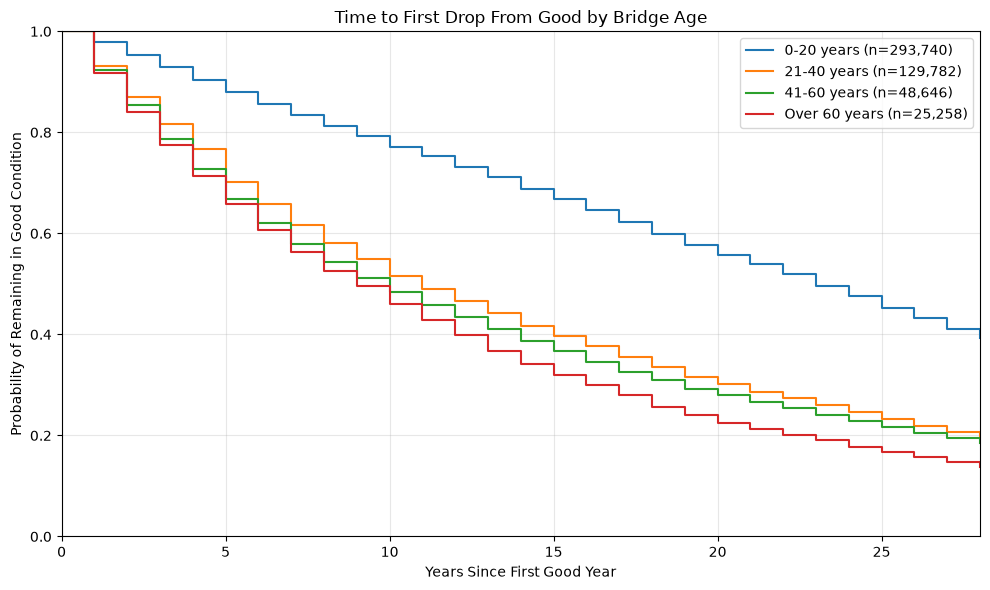

Bridges included: 497426

Bridges by age group:
age_group
0-20 years       293740
21-40 years      129782
41-60 years       48646
Over 60 years     25258
Name: count, dtype: int64


In [4]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

age_data = train.dropna(subset=["bridge_age"]).copy()

# Age at the beginning of observation
age_data["age_group"] = pd.cut(
    age_data["bridge_age"],
    bins=[-float("inf"), 20, 40, 60, float("inf")],
    labels=["0-20 years", "21-40 years", "41-60 years", "Over 60 years"],
    right=True
)

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group in age_data["age_group"].cat.categories:
    subset = age_data[age_data["age_group"] == group]

    kmf.fit(
        durations=subset["duration"],
        event_observed=subset["event"],
        label=f"{group} (n={len(subset):,})"
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Time to First Drop From Good by Bridge Age")
plt.xlabel("Years Since First Good Year")
plt.ylabel("Probability of Remaining in Good Condition")
plt.xlim(0, 28)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Bridges included:", len(age_data))
print("\nBridges by age group:")
print(age_data["age_group"].value_counts().sort_index())

# 4. Kaplan-Meier Analysis by Traffic Volume

Investigate whether average daily traffic (ADT) is associated with time to first drop from Good.

Compare bridges across traffic-volume groups using Kaplan-Meier survival curves. These comparisons are unadjusted and do not establish causation.

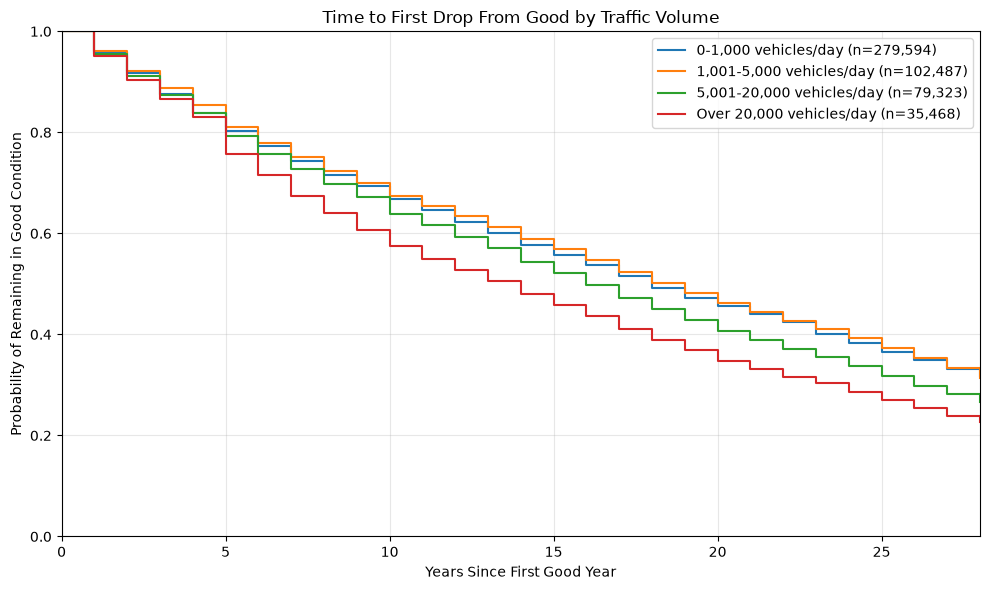

Bridges included: 496872

Bridges by traffic group:
traffic_group
0-1,000 vehicles/day         279594
1,001-5,000 vehicles/day     102487
5,001-20,000 vehicles/day     79323
Over 20,000 vehicles/day      35468
Name: count, dtype: int64


In [5]:
traffic_data = train.dropna(subset=["ADT_029"]).copy()

# Remove invalid negative traffic values
traffic_data = traffic_data[
    traffic_data["ADT_029"] >= 0
].copy()

# Group bridges by average daily traffic
traffic_data["traffic_group"] = pd.cut(
    traffic_data["ADT_029"],
    bins=[-1, 1000, 5000, 20000, float("inf")],
    labels=[
        "0-1,000 vehicles/day",
        "1,001-5,000 vehicles/day",
        "5,001-20,000 vehicles/day",
        "Over 20,000 vehicles/day"
    ]
)

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group in traffic_data["traffic_group"].cat.categories:
    subset = traffic_data[
        traffic_data["traffic_group"] == group
    ]

    if len(subset) == 0:
        continue

    kmf.fit(
        durations=subset["duration"],
        event_observed=subset["event"],
        label=f"{group} (n={len(subset):,})"
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Time to First Drop From Good by Traffic Volume")
plt.xlabel("Years Since First Good Year")
plt.ylabel("Probability of Remaining in Good Condition")
plt.xlim(0, 28)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Bridges included:", len(traffic_data))

print("\nBridges by traffic group:")
print(
    traffic_data["traffic_group"]
    .value_counts()
    .sort_index()
)

# 5. Kaplan-Meier Analysis by Structure Length

Investigate whether bridge length is associated with time to first drop from Good.

Compare Kaplan-Meier survival curves across bridge length categories. The results describe unadjusted associations and do not establish causation.

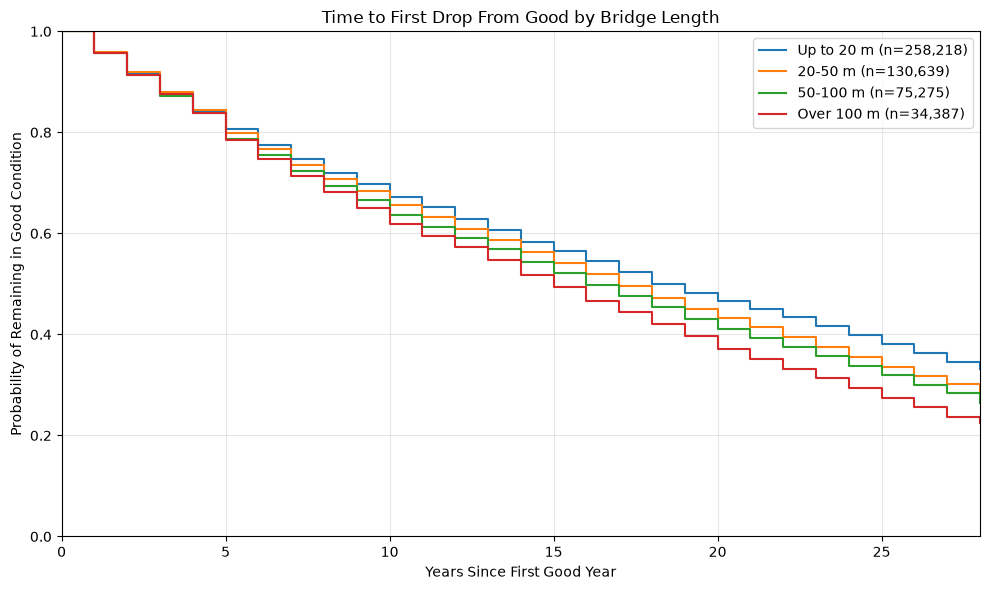

Bridges included: 498519

Bridges by length group:
length_group
Up to 20 m    258218
20-50 m       130639
50-100 m       75275
Over 100 m     34387
Name: count, dtype: int64


In [6]:
length_data = train.dropna(
    subset=["STRUCTURE_LEN_MT_049"]
).copy()

# Exclude invalid lengths
length_data = length_data[
    length_data["STRUCTURE_LEN_MT_049"] > 0
].copy()

# Group bridges by structure length
length_data["length_group"] = pd.cut(
    length_data["STRUCTURE_LEN_MT_049"],
    bins=[0, 20, 50, 100, float("inf")],
    labels=[
        "Up to 20 m",
        "20-50 m",
        "50-100 m",
        "Over 100 m"
    ]
)

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group in length_data["length_group"].cat.categories:
    subset = length_data[
        length_data["length_group"] == group
    ]

    if len(subset) == 0:
        continue

    kmf.fit(
        durations=subset["duration"],
        event_observed=subset["event"],
        label=f"{group} (n={len(subset):,})"
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Time to First Drop From Good by Bridge Length")
plt.xlabel("Years Since First Good Year")
plt.ylabel("Probability of Remaining in Good Condition")
plt.xlim(0, 28)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Bridges included:", len(length_data))

print("\nBridges by length group:")
print(
    length_data["length_group"]
    .value_counts()
    .sort_index()
)

# 6. Kaplan-Meier Analysis by Construction Material

Investigate how time to first drop from Good differs across bridge construction materials.

First, inspect the NBI structure-kind codes and sample sizes before generating Kaplan-Meier survival curves.

In [7]:
material_summary = (
    train.groupby("STRUCTURE_KIND_043A", dropna=False)
    .agg(
        bridges=("bridge_id", "count"),
        deterioration_events=("event", "sum")
    )
    .reset_index()
    .sort_values("bridges", ascending=False)
)

material_summary["percentage"] = (
    material_summary["bridges"] / len(train) * 100
).round(2)

print("Construction material categories:")
display(material_summary)

print("\nTotal bridges:", len(train))
print(
    "Missing material codes:",
    train["STRUCTURE_KIND_043A"].isna().sum()
)

Construction material categories:


,STRUCTURE_KIND_043A,bridges,deterioration_events,percentage
1,1,159707,70321,32.01
5,5,124902,47660,25.04
3,3,81320,49180,16.30
2,2,58311,29737,11.69
4,4,33287,19503,6.67
6,6,22091,8168,4.43
7,7,15598,10926,3.13
9,9,1470,522,0.29
0,0,1226,660,0.25
8,8,615,405,0.12



Total bridges: 498875
Missing material codes: 348


## 6.2 Kaplan-Meier Survival Curves by Construction Material

Compare time to first drop from Good across concrete, steel, prestressed concrete, and timber bridges.

Related NBI material codes are grouped together for clearer comparison. These curves show unadjusted associations and do not establish the physical causes of deterioration.

Concrete: 218,018 bridges
Steel: 114,607 bridges
Prestressed concrete: 146,993 bridges
Timber: 15,598 bridges


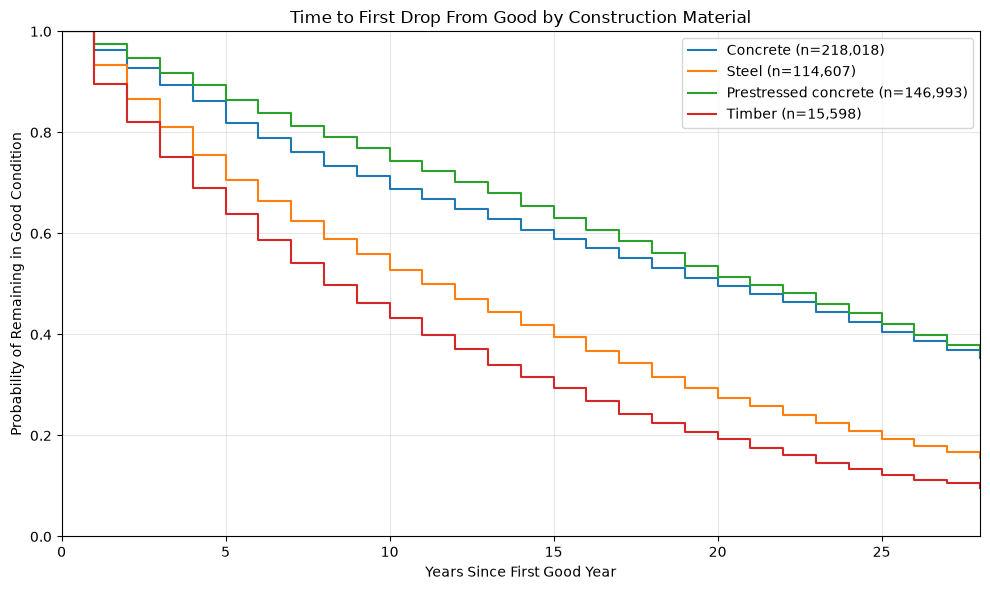


Total bridges included: 495216


In [8]:
# NBI material codes
material_map = {
    1: "Concrete",
    2: "Concrete",
    3: "Steel",
    4: "Steel",
    5: "Prestressed concrete",
    6: "Prestressed concrete",
    7: "Timber"
}

material_data = train.copy()

# Convert codes to numeric so they match the dictionary keys
material_data["material_code"] = pd.to_numeric(
    material_data["STRUCTURE_KIND_043A"],
    errors="coerce"
)

material_data["material_group"] = (
    material_data["material_code"].map(material_map)
)

# Keep only the four main material groups
material_data = material_data.dropna(
    subset=["material_group"]
)

material_order = [
    "Concrete",
    "Steel",
    "Prestressed concrete",
    "Timber"
]

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for material in material_order:
    subset = material_data[
        material_data["material_group"] == material
    ]

    print(f"{material}: {len(subset):,} bridges")

    if subset.empty:
        continue

    kmf.fit(
        durations=subset["duration"],
        event_observed=subset["event"],
        label=f"{material} (n={len(subset):,})"
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Time to First Drop From Good by Construction Material")
plt.xlabel("Years Since First Good Year")
plt.ylabel("Probability of Remaining in Good Condition")
plt.xlim(0, 28)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTotal bridges included:", len(material_data))

# 7. Kaplan-Meier Analysis by Structural Type

Investigate how time to first drop from Good differs across structural configurations.

First, inspect the structural type codes and their frequencies to identify meaningful categories for comparison.

In [9]:
type_summary = (
    train.groupby("STRUCTURE_TYPE_043B", dropna=False)
    .agg(
        bridges=("bridge_id", "count"),
        deterioration_events=("event", "sum")
    )
    .reset_index()
    .sort_values("bridges", ascending=False)
)

type_summary["percentage"] = (
    type_summary["bridges"] / len(train) * 100
).round(2)

print("Structural type categories:")
display(type_summary)

print("\nTotal bridges:", len(train))
print(
    "Missing structural type codes:",
    train["STRUCTURE_TYPE_043B"].isna().sum()
)

Structural type categories:


,STRUCTURE_TYPE_043B,bridges,deterioration_events,percentage
2,02,185181,96209,37.12
19,19,133757,51112,26.81
1,01,65634,33264,13.16
5,05,52900,24108,10.60
4,04,24311,14742,4.87
6,06,9074,2964,1.82
22,22,8070,3910,1.62
7,07,4516,1920,0.91
3,03,4037,2549,0.81
0,00,3225,1613,0.65



Total bridges: 498875
Missing structural type codes: 389


## 7.2 Kaplan-Meier Survival Curves by Structural Type

Compare time to first drop from Good for the five most common NBI structural types.

The curves represent unadjusted associations. Structural type may be related to construction material, bridge age, traffic volume and other characteristics.

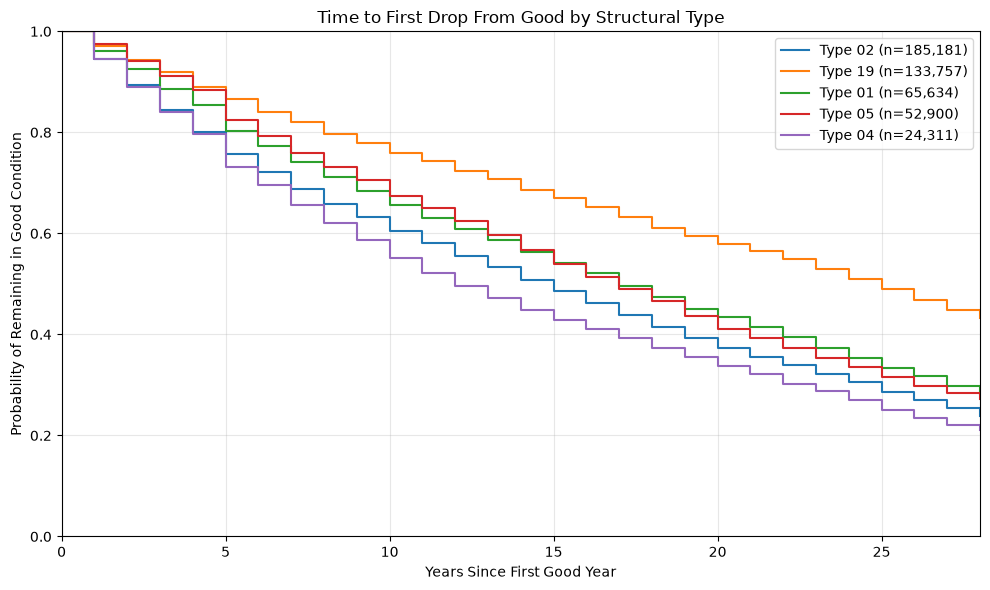

Total bridges included: 461783

Bridges by structural type:
type_code
02    185181
19    133757
01     65634
05     52900
04     24311
Name: count, dtype: Int64


In [10]:
# Five most common NBI structural type codes
top_types = ["02", "19", "01", "05", "04"]

type_data = train.copy()

# Standardise codes to two-digit strings
type_data["type_code"] = (
    type_data["STRUCTURE_TYPE_043B"]
    .astype("string")
    .str.strip()
    .str.zfill(2)
)

type_data = type_data[
    type_data["type_code"].isin(top_types)
].copy()

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for type_code in top_types:
    subset = type_data[
        type_data["type_code"] == type_code
    ]

    if subset.empty:
        continue

    kmf.fit(
        durations=subset["duration"],
        event_observed=subset["event"],
        label=f"Type {type_code} (n={len(subset):,})"
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Time to First Drop From Good by Structural Type")
plt.xlabel("Years Since First Good Year")
plt.ylabel("Probability of Remaining in Good Condition")
plt.xlim(0, 28)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Total bridges included:", len(type_data))

print("\nBridges by structural type:")
print(
    type_data["type_code"]
    .value_counts()
    .reindex(top_types)
)

# 8. Age-Stratified Material Comparisons

## 8.1 Kaplan-Meier Survival Curves by Material Within Age Groups

The earlier Kaplan-Meier analysis showed that steel and timber bridges had lower probabilities of remaining in Good condition than concrete and prestressed concrete bridges.

However, differences in bridge age may partly explain these patterns.

This analysis compares construction materials within the same bridge-age groups to investigate whether material-related differences persist among bridges of similar ages.

These comparisons remain observational and do not establish causation.

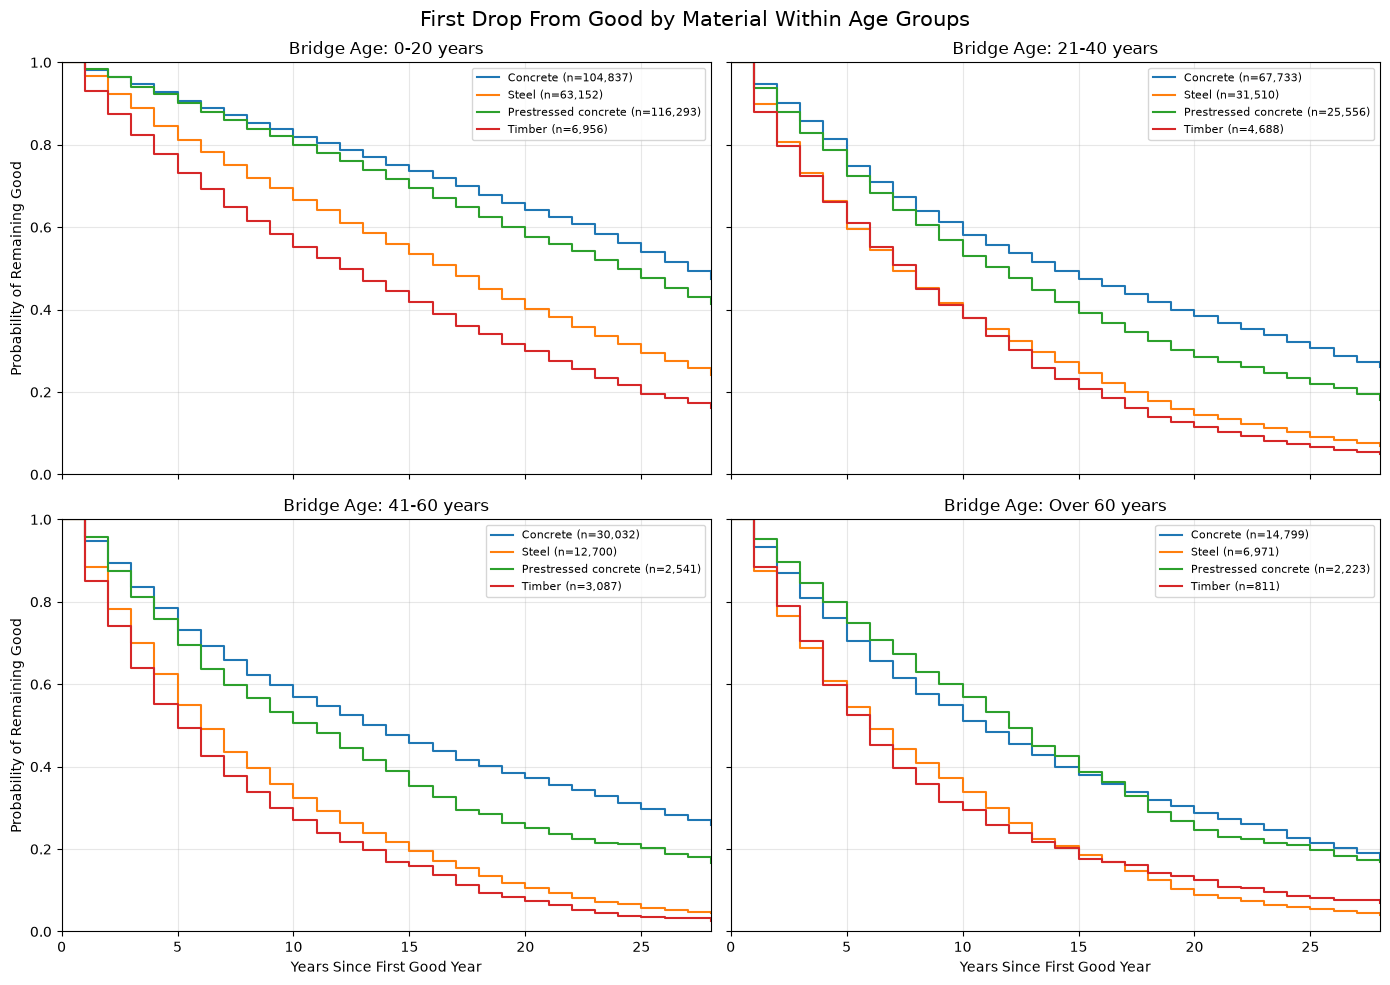

Bridges by age group and material:


material_group,Concrete,Steel,Prestressed concrete,Timber
age_group,,,,
0-20 years,104837,63152,116293,6956
21-40 years,67733,31510,25556,4688
41-60 years,30032,12700,2541,3087
Over 60 years,14799,6971,2223,811


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Use the material groups created in Section 6
age_material_data = material_data.dropna(
    subset=["bridge_age", "material_group"]
).copy()

# Same age groups used in Section 3
age_material_data["age_group"] = pd.cut(
    age_material_data["bridge_age"],
    bins=[-float("inf"), 20, 40, 60, float("inf")],
    labels=[
        "0-20 years",
        "21-40 years",
        "41-60 years",
        "Over 60 years"
    ]
)

material_order = [
    "Concrete",
    "Steel",
    "Prestressed concrete",
    "Timber"
]

age_order = [
    "0-20 years",
    "21-40 years",
    "41-60 years",
    "Over 60 years"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharex=True,
    sharey=True
)

for ax, age_group in zip(axes.flat, age_order):

    age_subset = age_material_data[
        age_material_data["age_group"] == age_group
    ]

    for material in material_order:

        subset = age_subset[
            age_subset["material_group"] == material
        ]

        if subset.empty:
            continue

        kmf = KaplanMeierFitter()

        kmf.fit(
            durations=subset["duration"],
            event_observed=subset["event"],
            label=f"{material} (n={len(subset):,})"
        )

        kmf.plot_survival_function(
            ax=ax,
            ci_show=False
        )

    ax.set_title(f"Bridge Age: {age_group}")
    ax.set_xlabel("Years Since First Good Year")
    ax.set_ylabel("Probability of Remaining Good")
    ax.set_xlim(0, 28)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    "First Drop From Good by Material Within Age Groups",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Display sample sizes
print("Bridges by age group and material:")

display(
    pd.crosstab(
        age_material_data["age_group"],
        age_material_data["material_group"]
    ).reindex(
        index=age_order,
        columns=material_order
    )
)

# 9. Does the Random Survival Forest agree with these patterns?

The improved RSF gives each test bridge a `risk_score` (higher means it is predicted to leave Good sooner). The test bridges are the 171,766 bridges still Good in 2021, followed through 2025.

For each characteristic we put three views side by side, group by group:

- Training Kaplan-Meier: share of bridges that have left Good by 10 years since the first Good year.
- Test outcome: events per 100 bridge-years of follow-up in 2021 to 2025.
- RSF: the mean risk percentile (0 to 100) of the group, where 100 means the highest predicted risk.

Agreement is measured with Spearman rank correlation across the groups of each characteristic. With only 3 to 5 groups this is a rough check, so read the plots and tables as well as the number.

Two cautions. Age in the test set is age in 2021, while age in the training set is age at the first Good year. The test event rate is not adjusted for how long a bridge had already been Good.

In [12]:
import numpy as np
from scipy.stats import spearmanr

rsf = pd.read_csv(project_root / "results/time_rsf_improved.csv")
print("RSF prediction file:", rsf.shape)
for col in ["bridge_id", "risk_score", "test_duration", "event"]:
    assert col in rsf.columns, f"missing column {col}"
assert rsf["bridge_id"].is_unique

test = pd.read_parquet(project_root / "data/final/bridge_survival_test_aligned.parquet")
char_cols = ["bridge_id", "bridge_age", "ADT_029", "STRUCTURE_LEN_MT_049", "STRUCTURE_KIND_043A", "STRUCTURE_TYPE_043B"]
missing = [c for c in char_cols if c not in test.columns]
assert not missing, f"test file is missing {missing}"

scored = rsf[["bridge_id", "risk_score", "test_duration", "event"]].merge(
    test[char_cols], on="bridge_id", how="left", validate="one_to_one", indicator=True
)
print(scored["_merge"].value_counts().to_string())
assert (scored["_merge"] == "both").all(), "some RSF bridges are not in the test file"
scored = scored.drop(columns="_merge")

# Percentile of each bridge's risk among all test bridges (100 = highest predicted risk)
scored["risk_percentile"] = scored["risk_score"].rank(pct=True) * 100
print("Test bridges:", f"{len(scored):,}", "| events:", f"{int(scored['event'].sum()):,}")

RSF prediction file: (171766, 9)
_merge
both          171766
left_only          0
right_only         0
Test bridges: 171,766 | events: 22,396


In [13]:
AGE_BINS = [-float("inf"), 20, 40, 60, float("inf")]
AGE_LABELS = ["0-20 years", "21-40 years", "41-60 years", "Over 60 years"]
TRAFFIC_BINS = [-1, 1000, 5000, 20000, float("inf")]
TRAFFIC_LABELS = ["0-1,000", "1,001-5,000", "5,001-20,000", "Over 20,000"]
LENGTH_BINS = [0, 20, 50, 100, float("inf")]
LENGTH_LABELS = ["Up to 20 m", "20-50 m", "50-100 m", "Over 100 m"]
MATERIAL_ORDER = ["Concrete", "Steel", "Prestressed concrete", "Timber"]
TYPE_ORDER = ["02", "19", "01", "05", "04"]

def add_groups(df):
    d = df.copy()
    d["age_group"] = pd.cut(d["bridge_age"], AGE_BINS, labels=AGE_LABELS)
    d["traffic_group"] = pd.cut(d["ADT_029"].where(d["ADT_029"] >= 0), TRAFFIC_BINS, labels=TRAFFIC_LABELS)
    d["length_group"] = pd.cut(d["STRUCTURE_LEN_MT_049"].where(d["STRUCTURE_LEN_MT_049"] > 0), LENGTH_BINS, labels=LENGTH_LABELS)
    mat = pd.to_numeric(d["STRUCTURE_KIND_043A"], errors="coerce").map(material_map)
    d["material_group"] = pd.Categorical(mat, categories=MATERIAL_ORDER)
    code_ = d["STRUCTURE_TYPE_043B"].astype("string").str.strip().str.zfill(2)
    d["type_group"] = pd.Categorical(code_.where(code_.isin(TYPE_ORDER)), categories=TYPE_ORDER)
    return d

train_g = add_groups(train)
scored_g = add_groups(scored)

CHARACTERISTICS = {
    "Bridge age": "age_group",
    "Traffic volume": "traffic_group",
    "Bridge length": "length_group",
    "Construction material": "material_group",
    "Structural type": "type_group",
}

## 9.1 Build the side-by-side tables

In [14]:
KM_YEAR = 10

def km_left_good(sub, year=KM_YEAR):
    """Share that has left Good by `year` years since first Good (Kaplan-Meier). NaN if no one is followed that long."""
    if len(sub) < 30 or sub["duration"].max() < year:
        return np.nan
    kmf = KaplanMeierFitter().fit(sub["duration"], sub["event"])
    return float(1 - kmf.predict(year))

tables = {}
for name, col in CHARACTERISTICS.items():
    rows = []
    for g in train_g[col].cat.categories:
        tr = train_g[train_g[col] == g]
        te = scored_g[scored_g[col] == g]
        if len(te) == 0:
            continue
        rows.append({
            "group": str(g),
            "train_bridges": len(tr),
            f"train_KM_left_good_by_{KM_YEAR}y_%": 100 * km_left_good(tr),
            "test_bridges": len(te),
            "test_events": int(te["event"].sum()),
            "test_events_per_100_bridge_years": 100 * te["event"].sum() / te["test_duration"].sum(),
            "RSF_mean_risk_percentile": te["risk_percentile"].mean(),
        })
    tables[name] = pd.DataFrame(rows)
    print(f"\n{name}")
    display(tables[name].round(2))


Bridge age


,group,train_bridges,train_KM_left_good_by_10y_%,test_bridges,test_events,test_events_per_100_bridge_years,RSF_mean_risk_percentile
0,0-20 years,293740,22.87,135766,15274,2.94,42.95
1,21-40 years,129782,48.41,23234,4475,5.24,75.46
2,41-60 years,48646,51.64,8896,1866,5.74,78.47
3,Over 60 years,25258,54.05,3596,751,5.73,80.63



Traffic volume


,group,train_bridges,train_KM_left_good_by_10y_%,test_bridges,test_events,test_events_per_100_bridge_years,RSF_mean_risk_percentile
0,"0-1,000",279594,33.10,96417,12358,3.38,47.33
1,"1,001-5,000",102487,32.57,36755,4860,3.49,49.90
2,"5,001-20,000",79323,36.11,26755,3615,3.57,55.72
3,"Over 20,000",35468,42.52,11432,1515,3.49,59.47



Bridge length


,group,train_bridges,train_KM_left_good_by_10y_%,test_bridges,test_events,test_events_per_100_bridge_years,RSF_mean_risk_percentile
0,Up to 20 m,258218,32.76,88062,11214,3.35,48.18
1,20-50 m,130639,34.43,45811,5800,3.33,49.69
2,50-100 m,75275,36.43,25424,3563,3.70,52.87
3,Over 100 m,34387,38.12,12422,1813,3.87,58.20



Construction material


,group,train_bridges,train_KM_left_good_by_10y_%,test_bridges,test_events,test_events_per_100_bridge_years,RSF_mean_risk_percentile
0,Concrete,218018,31.21,78610,9958,3.33,44.24
1,Steel,114607,47.32,26021,4255,4.38,70.05
2,Prestressed concrete,146993,25.71,64089,7526,3.08,48.22
3,Timber,15598,56.71,1747,502,8.05,74.37



Structural type


,group,train_bridges,train_KM_left_good_by_10y_%,test_bridges,test_events,test_events_per_100_bridge_years,RSF_mean_risk_percentile
0,02,185181,39.60,58937,8117,3.64,54.97
1,19,133757,24.07,55291,6586,3.13,42.25
2,01,65634,34.41,21617,3110,3.79,48.09
3,05,52900,32.58,17330,2030,3.08,57.69
4,04,24311,44.92,5512,762,3.66,52.21


## 9.2 Plots: the three views for each characteristic

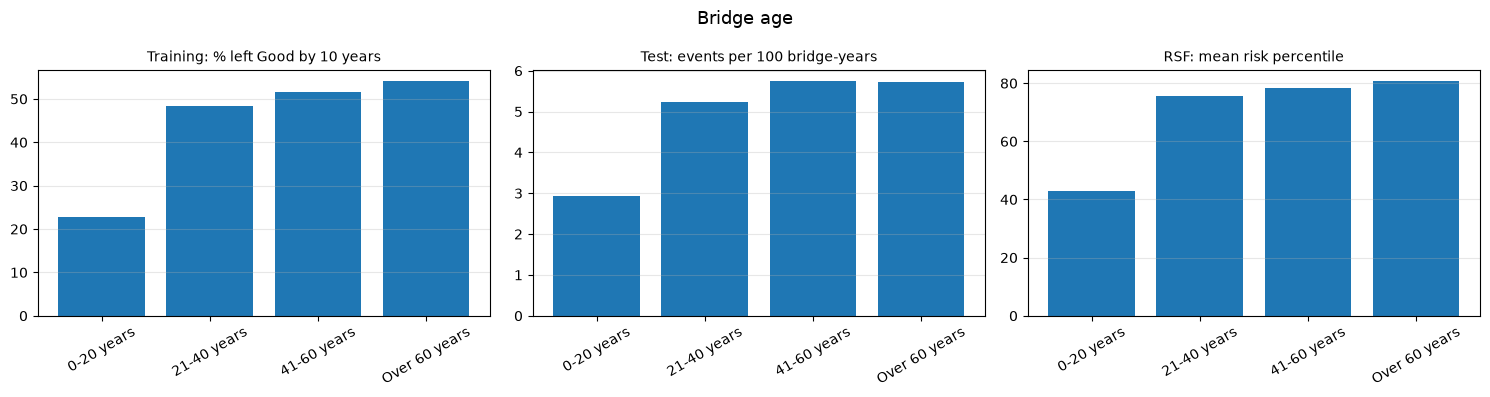

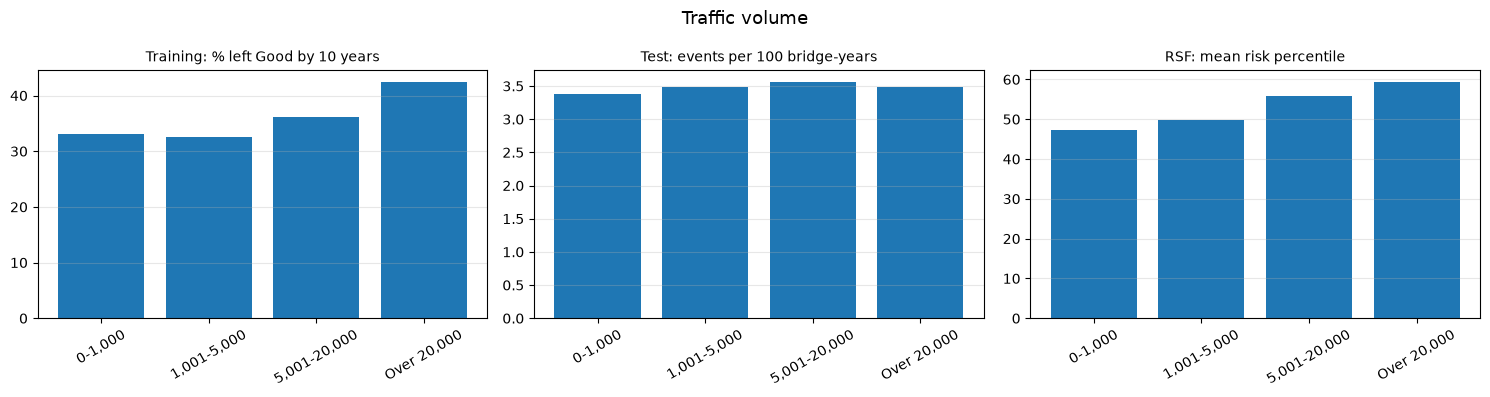

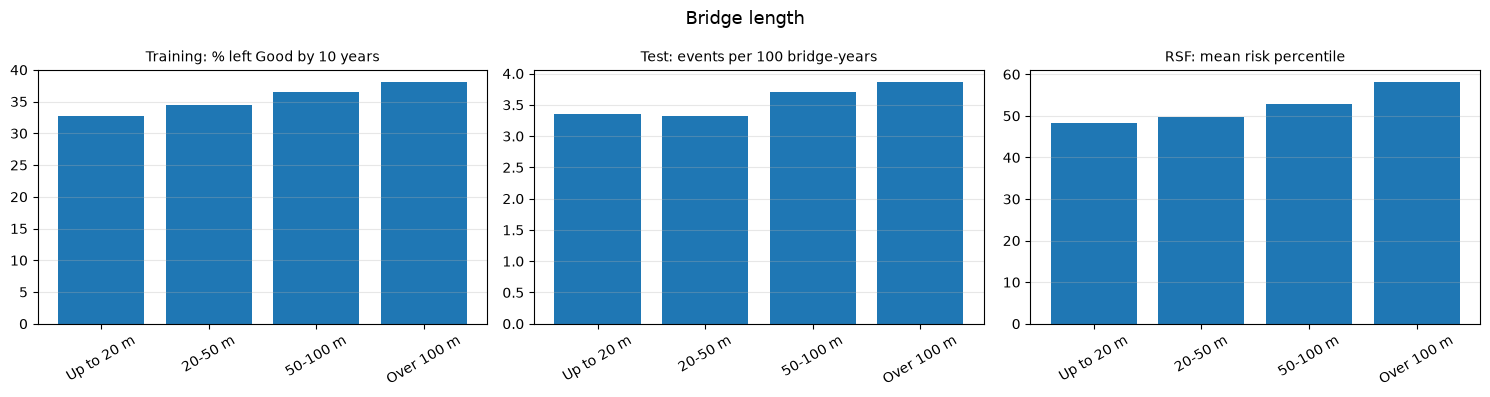

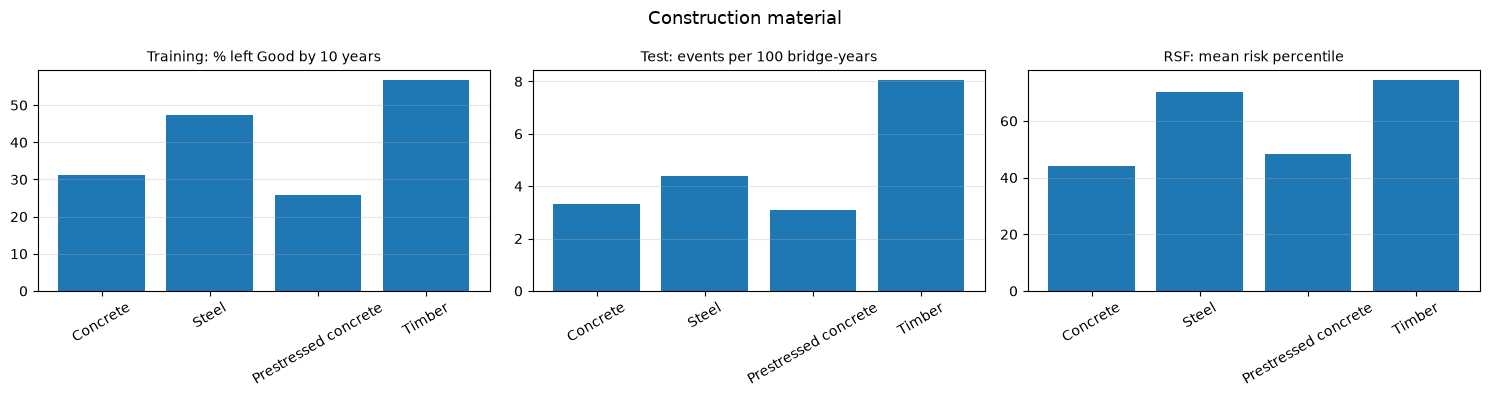

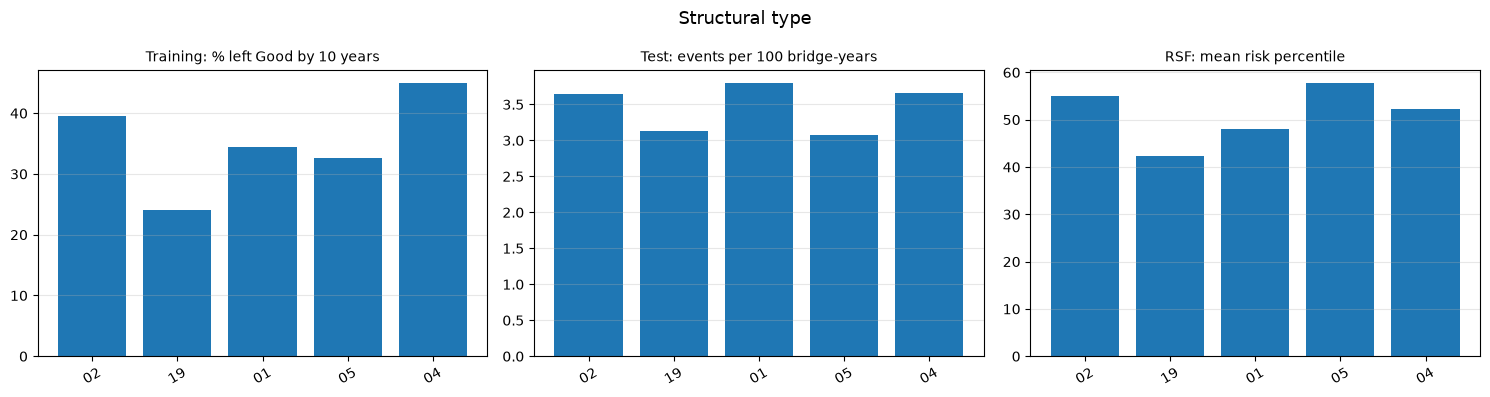

In [15]:
km_col = f"train_KM_left_good_by_{KM_YEAR}y_%"
for name, t in tables.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    panels = [
        (km_col, f"Training: % left Good by {KM_YEAR} years"),
        ("test_events_per_100_bridge_years", "Test: events per 100 bridge-years"),
        ("RSF_mean_risk_percentile", "RSF: mean risk percentile"),
    ]
    for ax, (c, title) in zip(axes, panels):
        ax.bar(t["group"], t[c])
        ax.set_title(title, fontsize=10)
        ax.tick_params(axis="x", rotation=30)
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()

## 9.3 Do the rankings agree?

Spearman correlation across the groups of each characteristic. +1 means the groups are ranked in exactly the same order, 0 means no relationship, -1 means the reverse order. The last columns show which group each source ranks as highest risk.

In [16]:
def rank_corr(a, b):
    ok = a.notna() & b.notna()
    if ok.sum() < 3:
        return np.nan
    return float(spearmanr(a[ok], b[ok])[0])

rows = []
for name, t in tables.items():
    rows.append({
        "characteristic": name,
        "groups": len(t),
        "RSF vs training KM": rank_corr(t["RSF_mean_risk_percentile"], t[km_col]),
        "RSF vs test events rate": rank_corr(t["RSF_mean_risk_percentile"], t["test_events_per_100_bridge_years"]),
        "training KM vs test events rate": rank_corr(t[km_col], t["test_events_per_100_bridge_years"]),
        "highest risk: training KM": t.loc[t[km_col].idxmax(), "group"] if t[km_col].notna().any() else "n/a",
        "highest risk: test events": t.loc[t["test_events_per_100_bridge_years"].idxmax(), "group"],
        "highest risk: RSF": t.loc[t["RSF_mean_risk_percentile"].idxmax(), "group"],
    })
agreement = pd.DataFrame(rows)
agreement.to_csv(project_root / "results/deterioration_factors_rsf_agreement.csv", index=False)
display(agreement.round(2))

,characteristic,groups,RSF vs training KM,RSF vs test events rate,training KM vs test events rate,highest risk: training KM,highest risk: test events,highest risk: RSF
0,Bridge age,4,1.0,0.8,0.8,Over 60 years,41-60 years,Over 60 years
1,Traffic volume,4,0.8,0.8,0.6,"Over 20,000","5,001-20,000","Over 20,000"
2,Bridge length,4,1.0,0.8,0.8,Over 100 m,Over 100 m,Over 100 m
3,Construction material,4,0.8,0.8,1.0,Timber,Timber,Timber
4,Structural type,5,0.3,-0.4,0.6,04,01,05


## 9.4 Does age explain the material and type differences?

Material and structural type are linked to age. A simple check is to look at the RSF risk percentile within age groups, so that a material gap that survives inside an age band is not just an age effect.

In [17]:
for col, order, label in [("material_group", MATERIAL_ORDER, "construction material"), ("type_group", TYPE_ORDER, "structural type")]:
    pivot = (scored_g.dropna(subset=["age_group", col])
             .groupby(["age_group", col], observed=True)["risk_percentile"].mean()
             .unstack(col).reindex(AGE_LABELS))
    print(f"Mean RSF risk percentile by age group and {label}:")
    display(pivot.round(1))

Mean RSF risk percentile by age group and construction material:


material_group,Concrete,Steel,Prestressed concrete,Timber
age_group,,,,
0-20 years,32.7,65.6,43.3,69.0
21-40 years,67.7,93.3,85.6,95.9
41-60 years,74.2,95.0,90.4,97.3
Over 60 years,76.6,95.6,86.6,96.2


Mean RSF risk percentile by age group and structural type:


type_group,02,19,01,05,04
age_group,,,,,
0-20 years,50.4,30.8,39.2,49.7,42.4
21-40 years,89.2,59.8,91.0,87.1,91.4
41-60 years,96.0,70.0,93.5,91.3,93.8
Over 60 years,94.9,72.3,92.0,87.5,93.6


# 10. Summary

In [18]:
print("Agreement between the RSF and the observed patterns")
print("-" * 52)
for _, r in agreement.iterrows():
    c1, c2 = r["RSF vs training KM"], r["RSF vs test events rate"]
    def word(x):
        if pd.isna(x): return "not enough groups to say"
        if x >= 0.8: return "strong agreement"
        if x >= 0.4: return "partial agreement"
        if x > -0.4: return "little agreement"
        return "disagreement"
    print(f"{r['characteristic']}: vs training KM {c1:.2f} ({word(c1)}); vs test event rate {c2:.2f} ({word(c2)})")
print()
print("Highest-risk group by source:")
display(agreement[["characteristic", "highest risk: training KM", "highest risk: test events", "highest risk: RSF"]])
print("Read this as consistency, not proof. Groups are unadjusted and overlap (older bridges are more often steel or timber, for example).")

Agreement between the RSF and the observed patterns
----------------------------------------------------
Bridge age: vs training KM 1.00 (strong agreement); vs test event rate 0.80 (partial agreement)
Traffic volume: vs training KM 0.80 (partial agreement); vs test event rate 0.80 (partial agreement)
Bridge length: vs training KM 1.00 (strong agreement); vs test event rate 0.80 (partial agreement)
Construction material: vs training KM 0.80 (partial agreement); vs test event rate 0.80 (partial agreement)
Structural type: vs training KM 0.30 (little agreement); vs test event rate -0.40 (little agreement)

Highest-risk group by source:


,characteristic,highest risk: training KM,highest risk: test events,highest risk: RSF
0,Bridge age,Over 60 years,41-60 years,Over 60 years
1,Traffic volume,"Over 20,000","5,001-20,000","Over 20,000"
2,Bridge length,Over 100 m,Over 100 m,Over 100 m
3,Construction material,Timber,Timber,Timber
4,Structural type,04,01,05


Read this as consistency, not proof. Groups are unadjusted and overlap (older bridges are more often steel or timber, for example).


## How to read this notebook

- The Kaplan-Meier curves in sections 3 to 8 describe the training histories. They show association, not cause.
- Section 9 asks whether the RSF ranks groups the same way. Agreement means the model has learned the same broad patterns. It does not show the model is correct for an individual bridge.
- Disagreement is not automatically a model fault. The curves are unadjusted, and the model uses condition ratings and other variables together.
- With 3 to 5 groups per characteristic the rank correlations are coarse. Quote them together with the tables.